In [2]:
import os, re, zipfile, glob, random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay
)

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

dataset_path = kagglehub.dataset_download(
    "shahliza27/ur-fall-detection-dataset"
)

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'ur-fall-detection-dataset' dataset.
Dataset downloaded to: /kaggle/input/ur-fall-detection-dataset


In [3]:
extract_path = "/content/urfd_rgb"
os.makedirs(extract_path, exist_ok=True)

zip_files = glob.glob(dataset_path + "/**/*.zip", recursive=True)

rgb_zips = [
    f for f in zip_files
    if re.search(r"(fall|adl)-\d+-cam0-rgb", os.path.basename(f), re.I)
]

print("RGB sequences found:", len(rgb_zips))

for z in rgb_zips:
    out_dir = os.path.join(
        extract_path, os.path.basename(z).replace(".zip", "")
    )
    os.makedirs(out_dir, exist_ok=True)

    with zipfile.ZipFile(z, "r") as archive:
        archive.extractall(out_dir)

print("Extraction complete.")

RGB sequences found: 0
Extraction complete.


Total sequences: 70
Falls: 30
ADL / non-falls: 40


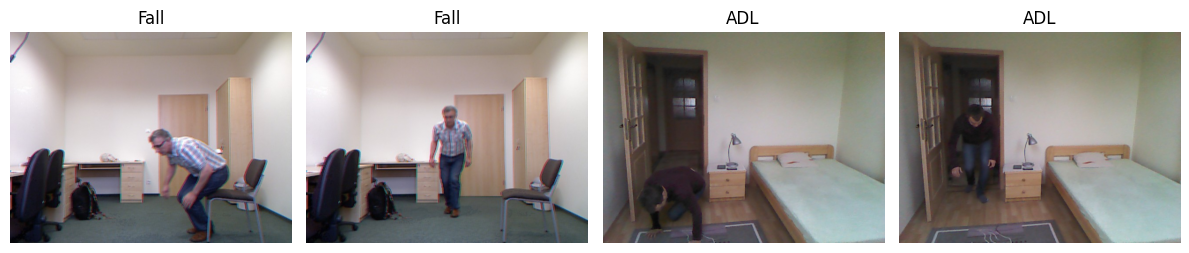

In [4]:
sequences = []

for root, dirs, files in os.walk(dataset_path):
    images = sorted([
        os.path.join(root, f)
        for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
    ])

    folder_name = os.path.basename(root).lower()

    if not images:
        continue

    if re.fullmatch(r"fall-\d+-cam0-rgb", folder_name):
        sequences.append((images, 1, folder_name))

    elif re.fullmatch(r"adl-\d+-cam0-rgb", folder_name):
        sequences.append((images, 0, folder_name))

print("Total sequences:", len(sequences))
print("Falls:", sum(label == 1 for _, label, _ in sequences))
print("ADL / non-falls:", sum(label == 0 for _, label, _ in sequences))

plt.figure(figsize=(12, 4))

for i, (images, label, name) in enumerate(
    random.sample(sequences, min(4, len(sequences)))
):
    frame = cv2.imread(images[len(images) // 2])
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 4, i + 1)
    plt.imshow(frame)
    plt.title("Fall" if label == 1 else "ADL")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
print("Dataset path:", dataset_path)

print("\nTop-level contents:")
for item in os.listdir(dataset_path):
    print(item)

print("\nZIP files found:")
zip_files = glob.glob(dataset_path + "/**/*.zip", recursive=True)
for f in zip_files[:30]:
    print(os.path.relpath(f, dataset_path))

print("\nFolders and sample files:")
for root, dirs, files in os.walk(dataset_path):
    if files:
        print("\nFolder:", os.path.relpath(root, dataset_path))
        print("Files:", files[:8])

Dataset path: /kaggle/input/ur-fall-detection-dataset

Top-level contents:
UR_fall_detection_dataset_cam0_rgb

ZIP files found:

Folders and sample files:

Folder: UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb
Files: ['adl-07-cam0-rgb-057.png', 'adl-07-cam0-rgb-034.png', 'adl-07-cam0-rgb-178.png', 'adl-07-cam0-rgb-126.png', 'adl-07-cam0-rgb-002.png', 'adl-07-cam0-rgb-103.png', 'adl-07-cam0-rgb-153.png', 'adl-07-cam0-rgb-174.png']

Folder: UR_fall_detection_dataset_cam0_rgb/adl-32-cam0-rgb
Files: ['adl-32-cam0-rgb-042.png', 'adl-32-cam0-rgb-015.png', 'adl-32-cam0-rgb-039.png', 'adl-32-cam0-rgb-102.png', 'adl-32-cam0-rgb-117.png', 'adl-32-cam0-rgb-189.png', 'adl-32-cam0-rgb-009.png', 'adl-32-cam0-rgb-057.png']

Folder: UR_fall_detection_dataset_cam0_rgb/adl-28-cam0-rgb
Files: ['adl-28-cam0-rgb-043.png', 'adl-28-cam0-rgb-055.png', 'adl-28-cam0-rgb-028.png', 'adl-28-cam0-rgb-050.png', 'adl-28-cam0-rgb-030.png', 'adl-28-cam0-rgb-040.png', 'adl-28-cam0-rgb-031.png', 'adl-28-cam0-rgb-083

In [6]:
FRAMES = 16
IMG_SIZE = 112

def load_video(images, augment_temporal=False):
    n = len(images)

    if n >= FRAMES:
        max_start = n - FRAMES
        start = random.randint(0, max_start) if augment_temporal else 0
        indices = np.linspace(
            start, min(start + FRAMES - 1, n - 1), FRAMES
        ).astype(int)
    else:
        indices = np.linspace(0, n - 1, FRAMES).astype(int)

    clip = []

    for idx in indices:
        frame = cv2.imread(images[idx])

        if frame is None:
            raise ValueError("Corrupted frame: " + images[idx])

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (IMG_SIZE, IMG_SIZE))
        clip.append(frame)

    return np.array(clip, dtype=np.uint8)

X, y, names = [], [], []

for images, label, name in sequences:
    try:
        X.append(load_video(images, augment_temporal=True))
        y.append(label)
        names.append(name)
    except (ValueError, cv2.error) as e:
        print("Skipped corrupted sequence:", name, e)

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int32)

print("Video tensor shape:", X.shape)
print("Labels shape:", y.shape)

Video tensor shape: (70, 16, 112, 112, 3)
Labels shape: (70,)


In [7]:
indices = np.arange(len(y))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=42, stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42,
    stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training:", len(train_idx), f"({len(train_idx)/len(y):.0%})")
print("Validation:", len(val_idx), f"({len(val_idx)/len(y):.0%})")
print("Testing:", len(test_idx), f"({len(test_idx)/len(y):.0%})")

Training: 49 (70%)
Validation: 10 (14%)
Testing: 11 (16%)


In [8]:
class VideoSequence(tf.keras.utils.Sequence):
    def __init__(self, X, y, batch_size=4, training=False):
        super().__init__()
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.training = training
        self.indices = np.arange(len(y))

    def __len__(self):
        return int(np.ceil(len(self.y) / self.batch_size))

    def on_epoch_end(self):
        if self.training:
            np.random.shuffle(self.indices)

    def __getitem__(self, index):
        ids = self.indices[index*self.batch_size:(index+1)*self.batch_size]
        batch = self.X[ids].copy().astype(np.float32) / 255.0

        if self.training:
            for i in range(len(batch)):
                # Random horizontal flip
                if random.random() < 0.5:
                    batch[i] = batch[i, :, :, ::-1, :]

                # Random crop and resize
                if random.random() < 0.5:
                    top = random.randint(0, 12)
                    left = random.randint(0, 12)
                    crop = batch[i, :, top:top+100, left:left+100, :]

                    batch[i] = np.array([
                        cv2.resize(frame, (IMG_SIZE, IMG_SIZE))
                        for frame in crop
                    ])

        return batch, self.y[ids]

train_gen = VideoSequence(X_train, y_train, training=True)
val_gen = VideoSequence(X_val, y_val)
test_gen = VideoSequence(X_test, y_test)

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int32(0): np.float64(0.875), np.int32(1): np.float64(1.1666666666666667)}


In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(FRAMES, IMG_SIZE, IMG_SIZE, 3)),

    tf.keras.layers.Conv3D(16, (3, 3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling3D((1, 2, 2)),

    tf.keras.layers.Conv3D(32, (3, 3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling3D((2, 2, 2)),

    tf.keras.layers.Conv3D(64, (3, 3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling3D((2, 2, 2)),

    tf.keras.layers.GlobalAveragePooling3D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,753 (292.00 KB)

 Trainable params: 74,753 (292.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    class_weight=class_weights
)

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 727ms/step - accuracy: 0.3878 - loss: 0.7003 - val_accuracy: 0.4000 - val_loss: 0.6976
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.5306 - loss: 0.6896 - val_accuracy: 0.5000 - val_loss: 0.6818
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.6531 - loss: 0.7114 - val_accuracy: 0.6000 - val_loss: 0.6861
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5918 - loss: 0.7016 - val_accuracy: 0.5000 - val_loss: 0.6899
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6327 - loss: 0.6818 - val_accuracy: 0.5000 - val_loss: 0.6676
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.6327 - loss: 0.6512 - val_accuracy: 0.5000 - val_loss: 0.7009
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.6939 - loss: 0.6279 - val_accuracy: 0.8000 - val_loss: 0.5105
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.6531 - loss: 0.5882 - val_accuracy: 0.5000 -

3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step
Accuracy : 0.7272727272727273
Precision: 1.0
Recall   : 0.4
F1-score : 0.5714285714285714
AUROC    : 0.8666666666666667

Classification Report:

                precision    recall  f1-score   support

Non-fall (ADL)       0.67      1.00      0.80         6
          Fall       1.00      0.40      0.57         5

      accuracy                           0.73        11
     macro avg       0.83      0.70      0.69        11
  weighted avg       0.82      0.73      0.70        11



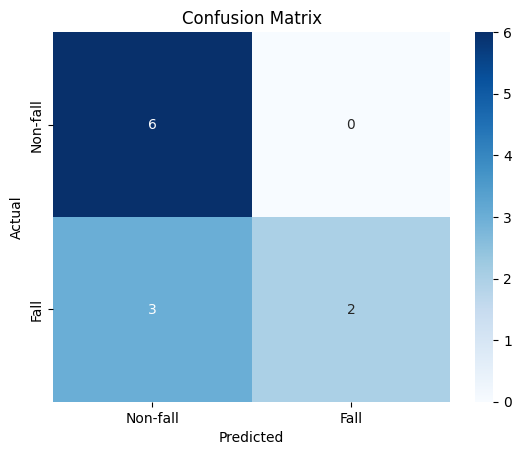

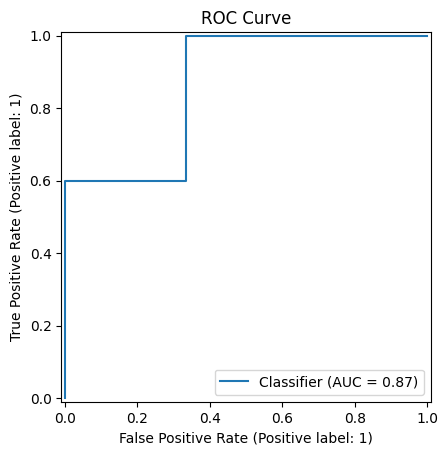

In [11]:
y_prob = model.predict(test_gen).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))
print("AUROC    :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:\n")
print(classification_report(
    y_test, y_pred, target_names=["Non-fall (ADL)", "Fall"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-fall", "Fall"],
    yticklabels=["Non-fall", "Fall"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.show()

Number of misclassified sequences: 3
Sequence: fall-06-cam0-rgb | Actual: Fall | Predicted: Non-fall


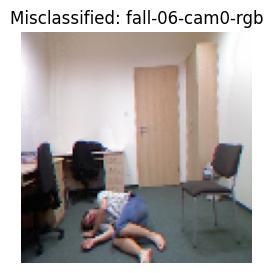

Sequence: fall-27-cam0-rgb | Actual: Fall | Predicted: Non-fall


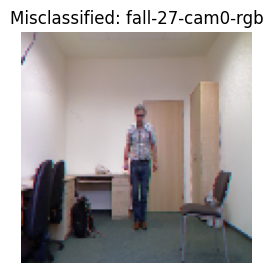

Sequence: fall-10-cam0-rgb | Actual: Fall | Predicted: Non-fall


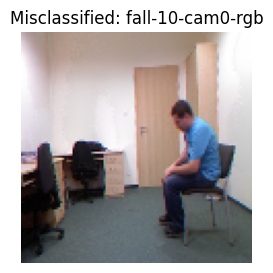

In [12]:
test_names = [names[i] for i in test_idx]

errors = np.where(y_test != y_pred)[0]

print("Number of misclassified sequences:", len(errors))

for i in errors:
    print(
        f"Sequence: {test_names[i]} | "
        f"Actual: {'Fall' if y_test[i] == 1 else 'Non-fall'} | "
        f"Predicted: {'Fall' if y_pred[i] == 1 else 'Non-fall'}"
    )

    clip = X_test[i]
    plt.figure(figsize=(4, 3))
    plt.imshow(clip[len(clip)//2])
    plt.title(f"Misclassified: {test_names[i]}")
    plt.axis("off")
    plt.show()

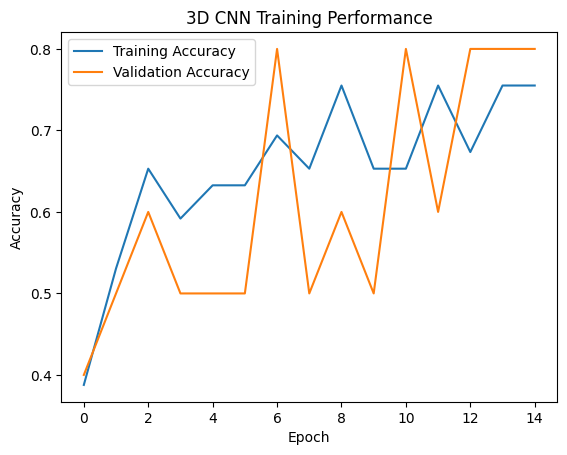

In [13]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("3D CNN Training Performance")
plt.legend()
plt.show()